In [33]:
import pandas as pd
from sklearn.naive_bayes import CategoricalNB
from sklearn.preprocessing import LabelEncoder
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.metrics import confusion_matrix

In [6]:
data = {
    'Age': ['Youth', 'Youth', 'Middle', 'Senior', 'Senior', 'Middle', 'Senior', 'Youth', 'Youth', 'Senior','Youth','Middle','Middle','Senior'],
    'Income': ['High', 'High', 'High', 'Medium', 'Low', 'Low', 'Low', 'Medium', 'Low', 'Medium', 'Medium', 'Medium','High', 'Medium'],
    'Student': ['No', 'No', 'No', 'No', 'Yes', 'Yes', 'Yes', 'No', 'Yes', 'Yes', 'Yes', 'No', 'Yes', 'No'],
    'Credit_Rating': ['Fair', 'Excellent', 'Fair', 'Fair', 'Fair', 'Excellent', 'Excellent', 'Fair', 'Fair','Fair', 'Excellent','Excellent','Fair','Excellent'],
    'Buys_Computer': ['No', 'No', 'Yes', 'Yes', 'Yes', 'No', 'Yes', 'No', 'Yes', 'Yes','Yes','Yes','Yes','No']
}

df = pd.DataFrame(data)
df

,Age,Income,Student,Credit_Rating,Buys_Computer
0,Youth,High,No,Fair,No
1,Youth,High,No,Excellent,No
2,Middle,High,No,Fair,Yes
3,Senior,Medium,No,Fair,Yes
4,Senior,Low,Yes,Fair,Yes
5,Middle,Low,Yes,Excellent,No
6,Senior,Low,Yes,Excellent,Yes
7,Youth,Medium,No,Fair,No
8,Youth,Low,Yes,Fair,Yes
9,Senior,Medium,Yes,Fair,Yes


In [20]:
le = {}
df_enc = df.copy()
for col in df_enc.columns:
    le[col] = LabelEncoder()
    df_enc[col] = le[col].fit_transform(df_enc[col])
df_enc

,Age,Income,Student,Credit_Rating,Buys_Computer
0,2,0,0,1,0
1,2,0,0,0,0
2,0,0,0,1,1
3,1,2,0,1,1
4,1,1,1,1,1
5,0,1,1,0,0
6,1,1,1,0,1
7,2,2,0,1,0
8,2,1,1,1,1
9,1,2,1,1,1


In [15]:
x = df_enc[['Age','Income', 'Student', 'Credit_Rating']]
y = df_enc['Buys_Computer']
x

,Age,Income,Student,Credit_Rating
0,2,0,0,1
1,2,0,0,0
2,0,0,0,1
3,1,2,0,1
4,1,1,1,1
5,0,1,1,0
6,1,1,1,0
7,2,2,0,1
8,2,1,1,1
9,1,2,1,1


In [16]:
model = CategoricalNB()
model.fit(x,y)


CategoricalNB()

In [18]:
test = [['Youth','Medium','Yes','Fair']]

In [19]:
print("\n---- Prediction ----------------------------------")
for t in test:
  row = [[
      le['Age'].transform([t[0]])[0],
      le['Income'].transform([t[1]])[0],
      le['Student'].transform([t[2]])[0],
      le['Credit_Rating'].transform([t[3]])[0]
  ]]
  pred = le['Buys_Computer'].inverse_transform(model.predict(row))[0]
  prob = model.predict_proba(row)[0]
  print(f"Input : Age =({t[0]}) Income =({t[1]}) Student =({t[2]}) Credit_Rating =({t[3]})")
  print(f"Output: Buys_Computer =({pred}")
  print(f"Result : Buys Computer -> {pred}")
  print(f"P(No) = {prob[0]:.4f}, P(Yes) = {prob[1]:.4f}")
  print("--------------------------------------------------")


---- Prediction ----------------------------------
Input : Age =(Youth) Income =(Medium) Student =(Yes) Credit_Rating =(Fair)
Output: Buys_Computer =(Yes
Result : Buys Computer -> Yes
P(No) = 0.2322, P(Yes) = 0.7678
--------------------------------------------------


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but CategoricalNB was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but CategoricalNB was fitted with feature names
  warnings.warn(


In [27]:
from sklearn.metrics import accuracy_score

y_pred = model.predict(x)
print(f"\n Training Accuracy: {accuracy_score(y,y_pred)*100:.2f}%")


 Training Accuracy: 78.57%


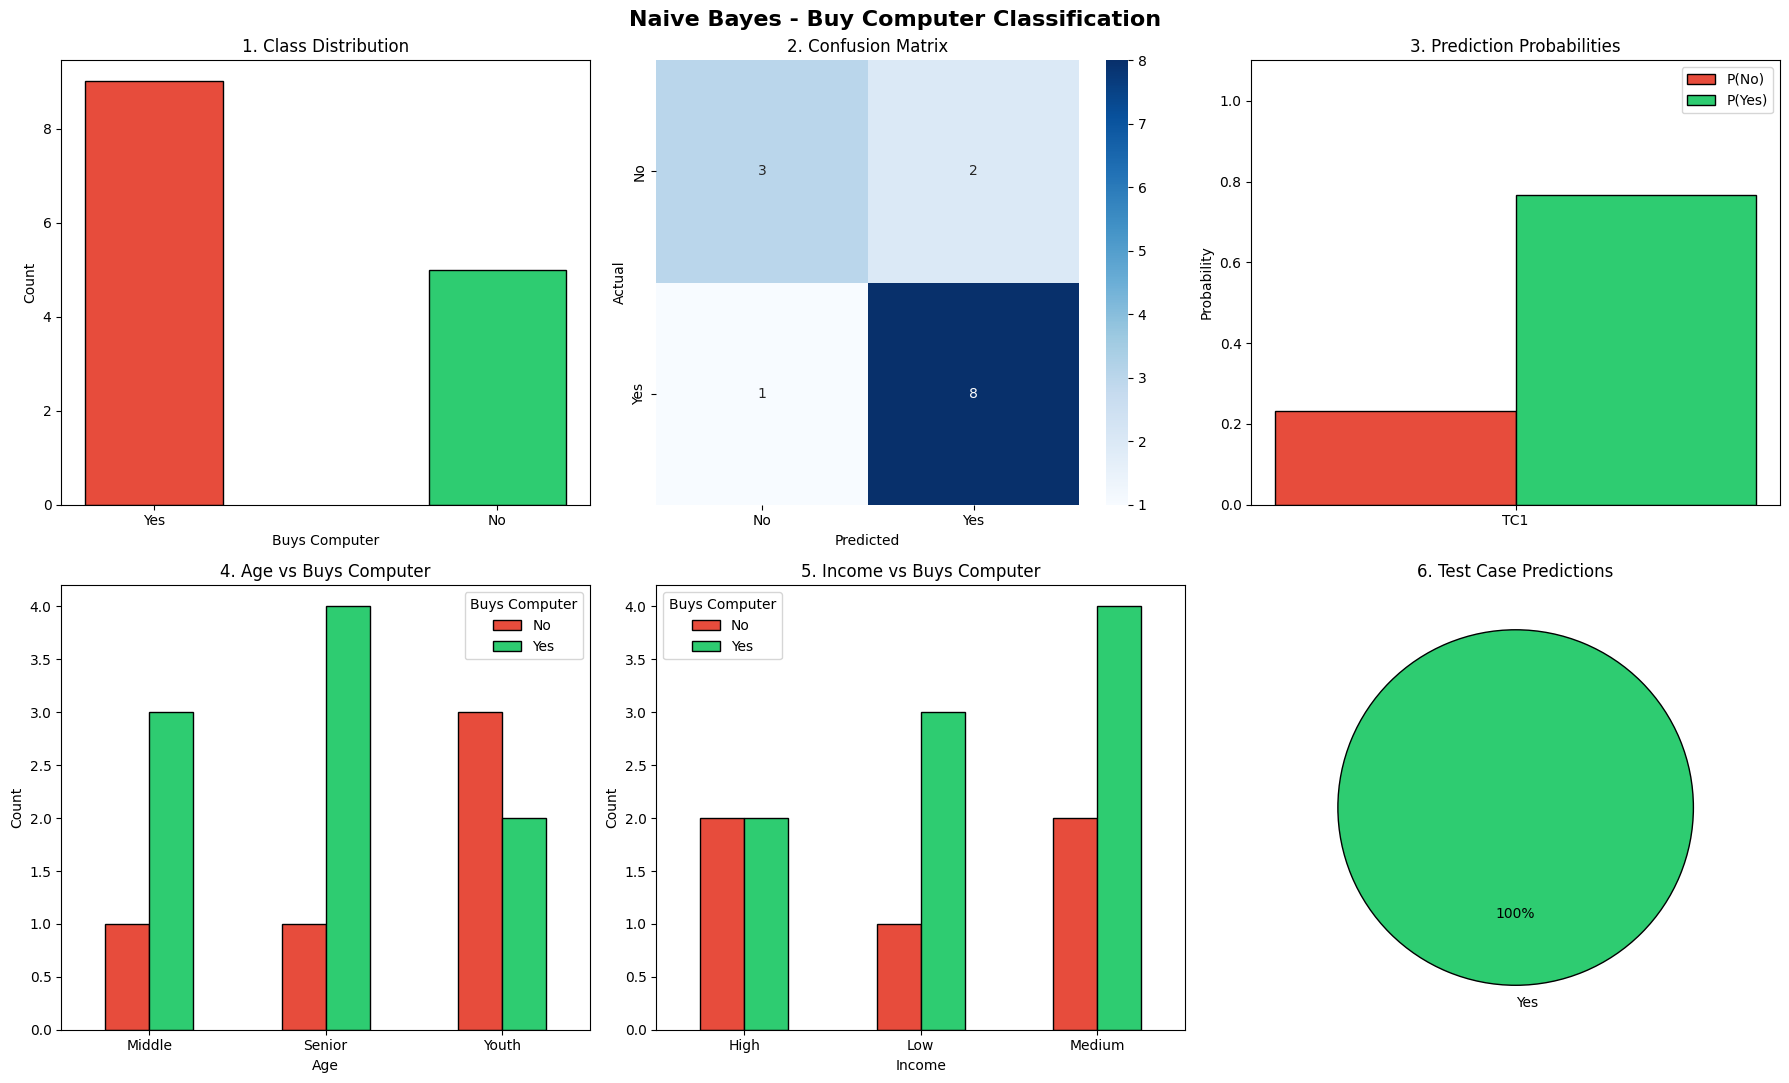

In [34]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.metrics import confusion_matrix

# Configure subplots
fig, axes = plt.subplots(2, 3, figsize=(18, 11))
fig.suptitle("Naive Bayes - Buy Computer Classification", fontsize=16, fontweight='bold')

# 1. Class Distribution
counts = df['Buys_Computer'].value_counts()
axes[0, 0].bar(counts.index, counts.values, color=['#e74c3c', '#2ecc71'], edgecolor='black', width=0.4)
axes[0, 0].set_title("1. Class Distribution")
axes[0, 0].set_xlabel("Buys Computer")
axes[0, 0].set_ylabel("Count")

# 2. Confusion Matrix
cm = confusion_matrix(y, model.predict(x))
sns.heatmap(cm, annot=True, cmap='Blues', xticklabels=['No','Yes'], yticklabels=['No','Yes'], ax=axes[0, 1], fmt='d')
axes[0, 1].set_title("2. Confusion Matrix")
axes[0, 1].set_xlabel("Predicted")
axes[0, 1].set_ylabel("Actual")

# Define test cases for visualization
test_cases = ["TC1"]
probs_no = [prob[0]]
probs_yes = [prob[1]]

# 3. Prediction Probabilities
tc_labels = [f"TC{i+1}" for i in range(len(test_cases))]
x_axis = np.arange(len(tc_labels))
w = 0.3
axes[0, 2].bar(x_axis - w/2, probs_no, w, label='P(No)', color='#e74c3c', edgecolor='black')
axes[0, 2].bar(x_axis + w/2, probs_yes, w, label='P(Yes)', color='#2ecc71', edgecolor='black')
axes[0, 2].set_title("3. Prediction Probabilities")
axes[0, 2].set_ylim(0, 1.1)
axes[0, 2].set_ylabel("Probability")
axes[0, 2].set_xticks(x_axis)
axes[0, 2].set_xticklabels(tc_labels)
axes[0, 2].legend()

# 4. Age vs Buys Computer
age_counts = df.groupby(['Age', 'Buys_Computer']).size().unstack(fill_value=0)
age_counts.plot(kind='bar', color=['#e74c3c', '#2ecc71'], edgecolor='black', rot=0, ax=axes[1, 0])
axes[1, 0].set_title("4. Age vs Buys Computer")
axes[1, 0].set_xlabel("Age")
axes[1, 0].set_ylabel("Count")
axes[1, 0].legend(title='Buys Computer')

# 5. Income vs Buys Computer
inc_counts = df.groupby(['Income', 'Buys_Computer']).size().unstack(fill_value=0)
inc_counts.plot(kind='bar', color=['#e74c3c', '#2ecc71'], edgecolor='black', rot=0, ax=axes[1, 1])
axes[1, 1].set_title("5. Income vs Buys Computer")
axes[1, 1].set_xlabel("Income")
axes[1, 1].set_ylabel("Count")
axes[1, 1].legend(title='Buys Computer')

# 6. Test Case Predictions
predictions = [pred]
pred_series = pd.Series(predictions)
pred_counts = pred_series.value_counts()
colors_pie = ['#2ecc71' if l == 'Yes' else '#e74c3c' for l in pred_counts.index]
axes[1, 2].pie(pred_counts.values, labels=pred_counts.index, colors=colors_pie, autopct='%1.0f%%', startangle=90, wedgeprops={'edgecolor': 'black'})
axes[1, 2].set_title("6. Test Case Predictions")

plt.tight_layout()
plt.show()